In [1]:
import numpy as np
import gurobipy as gp
from gurobipy import GRB

# Coordinates and weights
fields = {
    "F001": (16.03, -14.75, 2.39),
    "F002": (15.92, -14.61, 1.90),
    "F003": (16.12, -14.80, 1.05),
    "F004": (15.75, -14.55, 1.75)
}
shops = {
    "S001": (15.95, -14.70),
    "S002": (16.05, -14.60),
    "S003": (15.80, -14.50),
    "S004": (16.10, -14.78),
    "S005": (15.98, -14.65)
}

fields_list = list(fields.keys())
shops_list = list(shops.keys())

# Distance matrix (NumPy-only version of cdist)
field_coords = np.array([[v[0], v[1]] for v in fields.values()])  # (F, 2)
shop_coords  = np.array([[v[0], v[1]] for v in shops.values()])   # (S, 2)
# distances[i, j] = Euclidean distance between field i and shop j
diff = field_coords[:, None, :] - shop_coords[None, :, :]          # (F, S, 2)
distances = np.linalg.norm(diff, axis=2)                           # (F, S)

# Model
model = gp.Model("facility_location")
x = model.addVars(shops_list, vtype=GRB.BINARY, name="OpenShop")
y = model.addVars(fields_list, shops_list, vtype=GRB.BINARY, name="Assign")

# Objective
model.setObjective(gp.quicksum(
    fields[f][2] * distances[i, j] * y[f, s]
    for i, f in enumerate(fields_list)
    for j, s in enumerate(shops_list)
), GRB.MINIMIZE)

# Constraints: each field assigned to exactly one shop
for f in fields_list:
    model.addConstr(gp.quicksum(y[f, s] for s in shops_list) == 1, name=f"Assign_{f}")

# Open-assign linkage
for f_i, f in enumerate(fields_list):
    for s_j, s in enumerate(shops_list):
        model.addConstr(y[f, s] <= x[s], name=f"Link_{f}_{s}")

# Limit number of open shops
k = 2
model.addConstr(gp.quicksum(x[s] for s in shops_list) <= k, name="OpenLimit")

model.optimize()

# Output solution
for s in shops_list:
    if x[s].X > 0.5:
        print(f"Open shop at {s}")
for f in fields_list:
    for s in shops_list:
        if y[f, s].X > 0.5:
            print(f"Assign field {f} to shop {s}")


Set parameter Username
Academic license - for non-commercial use only - expires 2025-09-18
Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (mac64[rosetta2] - Darwin 23.4.0 23E224)

CPU model: Apple M1 Pro
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 25 rows, 25 columns and 65 nonzeros
Model fingerprint: 0x2dfbfffe
Variable types: 0 continuous, 25 integer (25 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [3e-02, 8e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Found heuristic solution: objective 1.2279346
Presolve time: 0.00s
Presolved: 25 rows, 25 columns, 65 nonzeros
Variable types: 0 continuous, 25 integer (25 binary)
Found heuristic solution: objective 1.0503143

Root relaxation: objective 6.447567e-01, 11 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incum

Matplotlib is building the font cache; this may take a moment.


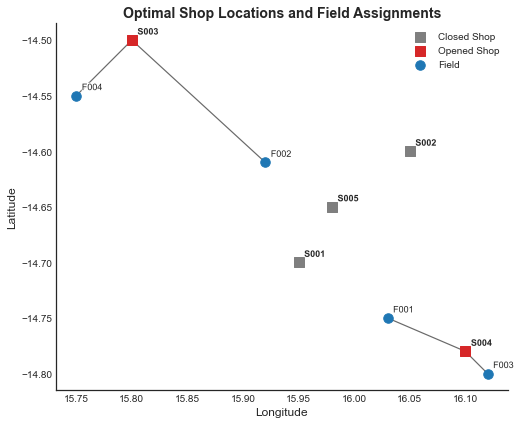

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# --- Style (robust to versions) ---
try:
    plt.style.use("seaborn-v0_8-white")  # works on newer Matplotlib
except Exception:
    plt.style.use("classic")             # safe fallback

fig, ax = plt.subplots(figsize=(8, 6))

# Colors
field_color = "#1f77b4"
open_shop_color = "#d62728"
closed_shop_color = "#7f7f7f"
line_color = "#444444"

# For a clean legend, we’ll add each label once
legend_added = {"Opened Shop": False, "Closed Shop": False, "Field": False}

# Plot shops
for s in shops_list:
    x_s, y_s = shops[s]
    is_open = getattr(x[s], "X", 0) > 0.5  # guard if x isn't solved yet
    lbl = "Opened Shop" if is_open else "Closed Shop"
    if legend_added[lbl]:
        lbl = None
    else:
        legend_added[lbl] = True

    ax.scatter(
        x_s, y_s,
        color=open_shop_color if is_open else closed_shop_color,
        marker="s", s=120 if is_open else 100,
        label=lbl,
        zorder=3
    )
    ax.text(
        x_s + 0.005, y_s + 0.005, s, fontsize=9, fontweight="bold",
        path_effects=[pe.withStroke(linewidth=2, foreground="white")]
    )

# Plot fields
for f in fields_list:
    x_f, y_f, _w = fields[f]
    lbl = None if legend_added["Field"] else "Field"
    legend_added["Field"] = True
    ax.scatter(x_f, y_f, color=field_color, s=90, label=lbl, zorder=2)
    ax.text(
        x_f + 0.005, y_f + 0.005, f, fontsize=9,
        path_effects=[pe.withStroke(linewidth=2, foreground="white")]
    )

# Draw assignment lines
for f in fields_list:
    for s in shops_list:
        if getattr(y[f, s], "X", 0) > 0.5:
            x_f, y_f, _ = fields[f]
            x_s, y_s = shops[s]
            ax.plot([x_f, x_s], [y_f, y_s],
                    linestyle="-", color=line_color,
                    linewidth=1.2, alpha=0.8, zorder=1)

# Final styling (your coordinates look like lon/lat; keep labels consistent)
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.set_title("Optimal Shop Locations and Field Assignments",
             fontsize=14, fontweight="bold")
ax.tick_params(labelsize=10)
ax.legend(fontsize=10, loc="upper right", frameon=False)
ax.set_aspect("equal")  # distances look better with equal aspect
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()
